In [1]:
import warnings
warnings.filterwarnings(
    "ignore",
    message=".*pin_memory.*no accelerator.*"
)


#### PYOD For Flow Logs: Threat Hunting Using an Ensemble Model
Part of the DUNE project (https://github.com/opendr-io/dune) and useful for hunting threats that are resistant to conventional detection or just hunting at great scale. This notebook does ensemble model anomaly detection using fields of your choice; this notebook is set upo for VPC flow logs and will run eighteen models by default; reduce as necessary if using higher cardinality fields. The notebook will score each row in the dataframe according to how many models evaluated it as an outlier. The scored anomalous events can be queried, sifted, aggregated, and sorted using the tools at the end. The notebook uses the pyod package which is on Github at: https://github.com/yzhao062/pyod and has docs here: https://pyod.readthedocs.io/en/latest/pyod.models.html

('d:\\.venv\\Scripts\\python.exe',
 '3.12.3 (tags/v3.12.3:f6650f9, Apr  9 2024, 14:05:25) [MSC v.1938 64 bit (AMD64)]',
 ['d:\\.venv', 'd:\\.venv\\Lib\\site-packages'],
 'd:\\aws exfil\\nbad')

In [ ]:
import datetime
from IPython.display import display
import re, textwrap
import plotly.graph_objects as go
import pandas as pd
import numpy as np
from numpy import percentile
import os
from random import randrange
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sys
import time
import torch
import sys, site, os 
sys.executable, sys.version, site.getsitepackages(), os.getcwd()

('d:\\.venv\\Scripts\\python.exe',
 '3.12.3 (tags/v3.12.3:f6650f9, Apr  9 2024, 14:05:25) [MSC v.1938 64 bit (AMD64)]',
 ['d:\\.venv', 'd:\\.venv\\Lib\\site-packages'],
 'd:\\aws exfil\\nbad')

In [4]:
from pyod.models.cblof import CBLOF
from pyod.models.cd import CD
from pyod.models.copod import COPOD
from pyod.models.dif import DIF
from pyod.models.ecod import ECOD
from pyod.models.gmm import GMM
from pyod.models.hbos import HBOS
from pyod.models.iforest import IForest
from pyod.models.inne import INNE
from pyod.models.kde import KDE
from pyod.models.knn import KNN
from pyod.models.lmdd import LMDD
from pyod.models.loda import LODA
from pyod.models.lof import LOF
from pyod.models.lunar import LUNAR
from pyod.models.pca import PCA
from pyod.models.ocsvm import OCSVM 
from pyod.models.qmcd import QMCD
from pyod.models.rod import ROD
from pyod.models.sod import SOD

In [49]:
# 1 - variables
pyod_out_frac=0.001   # share of sessions flagged per model (PYOD_DISTINCT = False)
random_state_number = 42
rs = np.random.RandomState(random_state_number)  #random state

# cores for the models that take n_jobs (KNN, AvKNN, LOF, IForest, CBLOF, COPOD, ECOD) and
# torch's thread count (DIF, LUNAR). A positive number = that many cores; -1 = every
# core, -2 = all but one, and so on (joblib's rule). ROD, CD, GMM, HBOS, INNE, LODA have
# no setting and use one core. Applied when cell 6 builds the models -- re-run from cell 6.
PYOD_N_JOBS = 3

_cpus = os.cpu_count() or 1
if not isinstance(PYOD_N_JOBS, int) or PYOD_N_JOBS == 0:
    raise ValueError(f"PYOD_N_JOBS must be a non-zero whole number, not {PYOD_N_JOBS!r}")
PYOD_CORES = PYOD_N_JOBS if PYOD_N_JOBS > 0 else max(1, _cpus + 1 + PYOD_N_JOBS)   # joblib's rule
print(f"Configured to use {PYOD_CORES} of {_cpus} cores (PYOD_N_JOBS = {PYOD_N_JOBS}) for the models that support it.")
if PYOD_CORES > _cpus:
    print(f"!! {PYOD_CORES} is more cores than this machine has -- the models will compete for {_cpus}")
if PYOD_CORES >= _cpus:
    print(f"!! that's every core on this machine -- other work here (other users, notebooks, the UI)"
          f" will slow down while the models run. PYOD_N_JOBS = -2 leaves one core free.")

# Distinct-rows mode: fit the models on each distinct combination of the feature values (a
# few thousand) instead of on every session (millions), with a log_count feature saying how
# many sessions share it; every session then gets its combination's votes. Same features;
# minutes -> seconds, and no blow-ups from duplicate rows (KNN, LOF). False = every session.
PYOD_DISTINCT = True
# log_count = log10(sessions with that combination), capped at log10(PYOD_COUNT_CAP): rare
# combinations spread out at the low end, and everything seen PYOD_COUNT_CAP or more times
# looks equally common. Uncapped, the few huge combinations looked like outliers.
PYOD_COUNT_CAP = 100
# In distinct mode each model flags this share of combinations, not sessions (0.001 of ~2,000
# combinations would be about 2). Replaces pyod_out_frac when PYOD_DISTINCT is True.
PYOD_DISTINCT_OUT_FRAC = 0.01
if PYOD_DISTINCT:
    pyod_out_frac = PYOD_DISTINCT_OUT_FRAC
print(f"PYOD_DISTINCT = {PYOD_DISTINCT}: models fit on "
      + (f"distinct combinations (log_count capped at {PYOD_COUNT_CAP:,}), each flagging {pyod_out_frac:.2%} of them"
         if PYOD_DISTINCT else f"every session, each flagging {pyod_out_frac:.2%} of them"))

# Quiet fits: PYOD_QUIET = True hides the models' chatter while they fit -- joblib's
# "[Parallel(n_jobs=3)] ..." lines (COPOD / ECOD print them whatever their settings) and
# repeated RuntimeWarnings (CD's divide by zero, COPOD / ECOD's "catastrophic cancellation"
# skew warning on near-constant columns). Each model then gets one line saying what was
# hidden. Errors still show. Used by the estimator and the runner.
PYOD_QUIET = True
import contextlib, io, warnings, collections

@contextlib.contextmanager
def pyod_quiet(hidden):
    """Collect warnings (as 'file: message' -> count) into the dict `hidden`, and drop stderr."""
    if not PYOD_QUIET:
        yield
        return
    _ignored = [f for f in warnings.filters if f[0] == "ignore"]   # e.g. cell 0's pin_memory filter
    with warnings.catch_warnings(record=True) as _w, contextlib.redirect_stderr(io.StringIO()):
        warnings.simplefilter("always")            # count every repeat, not just the first...
        warnings.filters[:0] = _ignored            # ...but warnings already ignored stay ignored
        try:
            yield
        finally:
            for _x in _w:
                _k = f"{os.path.basename(_x.filename)}: {str(_x.message).split('.')[0][:70]}"
                hidden[_k] = hidden.get(_k, 0) + 1

def pyod_hidden_note(hidden):
    """'    (hidden: cd.py: invalid value encountered in divide x9)' or ''"""
    return ("    (hidden: " + "; ".join(f"{k} x{n}" for k, n in hidden.items()) + ")") if hidden else ""

Configured to use 3 of 4 cores (PYOD_N_JOBS = 3) for the models that support it.
PYOD_DISTINCT = True: models fit on distinct combinations (log_count capped at 100), each flagging 1.00% of them


In [8]:
# 3 - for parquet loading
pyod_input = pd.read_parquet("vflowsAgg-637602092272-november-2026.parquet")
# Drop NODATA / SKIPDATA records (log-status): no addresses, ports, protocol or traffic --
# every field empty, which the models treat as an extreme value and rank highly.
if "log-status" in pyod_input.columns:
    _empty = pyod_input["log-status"].isin(["NODATA", "SKIPDATA"])
    print(f"dropped {int(_empty.sum()):,} NODATA / SKIPDATA rows, {int((~_empty).sum()):,} left")
    pyod_input = pyod_input[~_empty].reset_index(drop=True)
# session_id: the session key joined with "|" -- the session itself, not a hash, so no two
# sessions can share one, and the same session gets the same ID in every run and notebook.
# The field order, separator and null handling below are the ID format: don't change them,
# or IDs from different runs won't match. Nulls (NODATA / SKIPDATA rows) become "".
# e.g. 637602092272|eni-02b85e2a3caf5dd60|52.216.24.124|443|172.16.200.168|46636|6|1583529747|ACCEPT
# Built with pyarrow compute (vectorized C++, one thread -- ~4x faster than pandas string
# concatenation) as string[pyarrow]. Not a feature -- keep it out of CARD_FIELDS.
import pyarrow as pa
import pyarrow.compute as pc

SESSION_KEY = ["account-id", "interface-id", "srcaddr", "srcport", "dstaddr", "dstport",
               "protocol", "start", "action"]
if _miss := [k for k in SESSION_KEY if k not in pyod_input.columns]:
    raise KeyError(f"can't build session_id -- not in the parquet: {_miss}")
_parts = []
for _k in SESSION_KEY:
    _s = pyod_input[_k]
    if pd.api.types.is_numeric_dtype(_s) and not pd.api.types.is_bool_dtype(_s):
        _s = _s.astype("Int64")                       # 443, never 443.0
    _parts.append(pc.fill_null(pc.cast(pa.array(_s, from_pandas=True), pa.string()), ""))
pyod_input["session_id"] = pd.Series(pd.arrays.ArrowStringArray(pc.binary_join_element_wise(*_parts, "|")),
                                     index=pyod_input.index)
if _nDup := int(pyod_input["session_id"].duplicated().sum()):
    print(f"!! {_nDup:,} rows share a session_id with another row -- the session key isn't unique in this file")

pyod_raw = pyod_input.copy()
print('raw data shape and column names:')
print(pyod_input.shape)
print()
print('Choose your field names:')
pyod_input.columns

dropped 6,682 NODATA / SKIPDATA rows, 3,616,571 left
raw data shape and column names:
(3616571, 30)

Choose your field names:


Index(['start', 'end', 'version', 'account-id', 'interface-id', 'srcaddr',
       'src-int', 'dstaddr', 'dst-int', 'srcport', 'dstport', 'protocol',
       'packets', 'bytes', 'action', 'log-status', 'start_time', 'end_time',
       'records', 'tag-src-public', 'tag-dst-public', 'tag-direction',
       'tag-org', 'tag-cloud', 'tag-asn', 'tag-cc', 'tag-country', 'conflict',
       'tag-service', 'session_id'],
      dtype='object')

In [9]:
# 4- Cardinality of the fields listed below (pyod_input). Edit the list: comment a line out
# to skip that field. A name pyod_input doesn't have is reported and skipped.
# Shows distinct values, share of rows that are distinct, nulls, dtype, and a few examples
# -- sorted by distinct values, highest first.

CARD_FIELDS = [
    "interface-id",
    "protocol",
    "action",
    "tag-direction",
    "tag-country",
    "tag-service"
]

_missing = [c for c in CARD_FIELDS if c not in pyod_input.columns]
if _missing:
    print(f"!! not in pyod_input, skipped: {_missing}")
_cf = [c for c in dict.fromkeys(CARD_FIELDS) if c in pyod_input.columns]

_n = len(pyod_input)
pyod_cardinality = pd.DataFrame({
    "distinct": [pyod_input[c].nunique(dropna=True) for c in _cf],
    "nulls":    [int(pyod_input[c].isna().sum()) for c in _cf],
    "dtype":    [str(pyod_input[c].dtype) for c in _cf],
    "examples": [", ".join(map(str, pyod_input[c].dropna().unique()[:3])) for c in _cf],
}, index=pd.Index(_cf, name="field"))
pyod_cardinality.insert(1, "distinct_pct", pyod_cardinality["distinct"] / max(_n, 1))
pyod_cardinality = pyod_cardinality.sort_values("distinct", ascending=False)

print(f"{_n:,} rows, {len(_cf)} fields")
pyod_cardinality.style.format({"distinct": "{:,}", "nulls": "{:,}", "distinct_pct": "{:.2%}"})

3,616,571 rows, 6 fields


,distinct,distinct_pct,nulls,dtype,examples
field,,,,,
tag-country,220,0.01%,10,string,"United States, Seychelles, China"
tag-service,41,0.00%,"2,200,941",string,"HTTPS, SMB, SSH"
interface-id,12,0.00%,0,object,"eni-02b85e2a3caf5dd60, eni-0f324b6f6044e4ef3, eni-0a98cf7cabe3677e3"
protocol,7,0.00%,0,Int64,"6, 17, 1"
tag-direction,2,0.00%,0,string,"north-south, east-west"
action,2,0.00%,0,object,"ACCEPT, REJECT"


In [10]:
# 5 - Select fields to encode and use for outlier detection: both take CARD_FIELDS from
# cell 4 (names pyod_input doesn't have are left out). Copies, so editing one list here
# doesn't change the other or CARD_FIELDS.
# Warns about any field with more than MAX_CARDINALITY distinct values -- as category codes,
# high-cardinality fields (addresses, ports, timestamps) give arbitrary numbers the models
# treat as distances.
pyod_fields_to_encode     = [c for c in CARD_FIELDS if c in pyod_input.columns]
pyod_columns_for_outliers = list(pyod_fields_to_encode)
print(f"{len(pyod_columns_for_outliers)} fields: {', '.join(pyod_columns_for_outliers)}")

MAX_CARDINALITY = 1000
_hiCard = {c: n for c in pyod_fields_to_encode if (n := pyod_input[c].nunique()) > MAX_CARDINALITY}
for _c, _n in sorted(_hiCard.items(), key=lambda kv: -kv[1]):
    print(f"!! {_c}: {_n:,} distinct values (> {MAX_CARDINALITY:,})")

6 fields: interface-id, protocol, action, tag-direction, tag-country, tag-service


In [11]:
# 6 - dictionary of classifiers
# defines a dictionary of anomaly detection models with configurations
# using various algorithms from libraries likely associated with
# PyOD (Python Outlier Detection).
# n_jobs / torch threads come from PYOD_N_JOBS in cell 1.
torch.set_num_threads(PYOD_CORES)
print(f"models: n_jobs = {PYOD_N_JOBS} ({PYOD_CORES} of {os.cpu_count()} cores), torch threads = {torch.get_num_threads()}")

clf = { 
    'CBLOF': CBLOF(contamination=pyod_out_frac, check_estimator=False, random_state=rs, n_jobs=PYOD_N_JOBS),
    'IForest': IForest(contamination=pyod_out_frac, random_state=rs, n_jobs=PYOD_N_JOBS),
    'KNN': KNN(contamination=pyod_out_frac, n_jobs=PYOD_N_JOBS),
    'AvKNN': KNN(method='mean', contamination=pyod_out_frac, n_jobs=PYOD_N_JOBS),
    'LOF':LOF(n_neighbors=35, contamination=pyod_out_frac, n_jobs=PYOD_N_JOBS),
     ### added new ####
    'ROD':ROD(contamination=pyod_out_frac),
    'CD' : CD(contamination=pyod_out_frac),
    'COPOD' : COPOD(contamination=pyod_out_frac, n_jobs=PYOD_N_JOBS),
    'ECOD' : ECOD(contamination=pyod_out_frac, n_jobs=PYOD_N_JOBS),
    'GMM' : GMM(contamination=pyod_out_frac),
    'HBOS' : HBOS(contamination=pyod_out_frac),
    'INNE' : INNE(contamination=pyod_out_frac),
    'LODA' : LODA(contamination=pyod_out_frac),
    'QMCD' : QMCD(contamination=pyod_out_frac),
    # Optional classifiers; these will take longer to run
    'OCSVM': OCSVM(contamination=pyod_out_frac), # One-class SVM 182 seconds
    'DIF': DIF(contamination=pyod_out_frac), # 148 seconds
    'KDE': KDE(contamination=pyod_out_frac), # 169 seconds
    'LUNAR': LUNAR(contamination=pyod_out_frac), # 227 seconds i.e. 4 minutes
} 

models: n_jobs = 3 (3 of 4 cores), torch threads = 3


In [12]:
# 7 - fractions
pyod_num_samples = pyod_input.shape[0]
pyod_fraction_of_inliers = (1. - pyod_out_frac) 
# (1 - fraction of outliers)
pyod_num_inliers = int(pyod_fraction_of_inliers * pyod_num_samples) 
# fraction of inliers * total number of samples
pyod_num_outliers = int(pyod_out_frac * pyod_num_samples) 
# fraction of outliers * total number of samples
print('No. of inliers: %i' % pyod_num_inliers)
print('No. of outliers: %i' % pyod_num_outliers)
print('dataframe shape:')
print(pyod_input.shape)

No. of inliers: 3580405
No. of outliers: 36165
dataframe shape:
(3616571, 30)


In [13]:
# 8 - convert the data type of each column to category
# replace the original categorical values with their 
# corresponding integer codes. 
for field in pyod_fields_to_encode:
    pyod_input[field] = pyod_input[field].astype('category')
    pyod_input[field] = pyod_input[field].cat.codes

In [14]:
# 9 - PX - the matrix the models fit on (cell 8 has encoded the fields as integer codes).
# PYOD_DISTINCT (cell 1): one row per distinct combination of pyod_columns_for_outliers, plus
# log_count as the last column. pyod_combo_id[i] = PX row of session i, and pyod_expand()
# turns per-combination votes into per-session ones (the runner uses it). Otherwise one row
# per session and pyod_expand() changes nothing.
_X = pyod_input.loc[:, pyod_columns_for_outliers].to_numpy()
if PYOD_DISTINCT:
    _uniq, _inv, pyod_combo_count = np.unique(_X, axis=0, return_inverse=True, return_counts=True)
    pyod_combo_id = _inv.reshape(-1)
    _logCount = np.log10(np.minimum(pyod_combo_count, PYOD_COUNT_CAP))
    PX = np.column_stack([_uniq, _logCount]).astype(float)
    pyod_expand = lambda y: np.asarray(y)[pyod_combo_id]
    print(f"{len(PX):,} distinct combinations of {len(pyod_columns_for_outliers)} fields in {len(_X):,} sessions; "
          f"sessions per combination: median {int(np.median(pyod_combo_count)):,}, max {int(pyod_combo_count.max()):,}; "
          f"{int((pyod_combo_count < PYOD_COUNT_CAP).sum()):,} combinations below the cap of {PYOD_COUNT_CAP:,}")
    print(f"each model flags about {int(pyod_out_frac * len(PX)):,} combinations")
    if len(PX) > 0.2 * len(_X):
        print("!! most sessions have their own combination -- distinct mode saves little here "
              "(a high-cardinality field?)")
else:
    pyod_combo_id, pyod_combo_count = None, None
    PX = _X
    pyod_expand = lambda y: y
    print(f"{len(PX):,} sessions x {PX.shape[1]} fields")

9,230 distinct combinations of 6 fields in 3,616,571 sessions; sessions per combination: median 5, max 344,126; 8,189 combinations below the cap of 100
each model flags about 92 combinations


In [15]:
# 10 - extract columns from a pandas DataFrame and convert them into a NumPy array. 
for i, classifier in enumerate(clf.keys()):
    print('Model', i + 1, ':' + classifier) 

Model 1 :CBLOF
Model 2 :IForest
Model 3 :KNN
Model 4 :AvKNN
Model 5 :LOF
Model 6 :ROD
Model 7 :CD
Model 8 :COPOD
Model 9 :ECOD
Model 10 :GMM
Model 11 :HBOS
Model 12 :INNE
Model 13 :LODA
Model 14 :QMCD
Model 15 :OCSVM
Model 16 :DIF
Model 17 :KDE
Model 18 :LUNAR


In [16]:
# 11 - iterates over a dictionary of classifiers and add a new column
# to the dataframe for each classifier to store classifications 
# initialized to zero
for i, (classifier_name, classifier) in enumerate(clf.items()):
    pyod_input[str('out_'+ classifier_name)] = 0

### Estimator: This cell will forecast runtimes for the loaded dataframe and remove any excessively expensive models according to runtime with a default limit of 60 seconds.

In [18]:
# 12 - PX comes from the PX cell above (distinct combinations or every session).
# Up to ESTIMATOR_DIRECT_ROWS rows, each model is simply timed on all of PX -- that's quick
# and exact. Above that, the sample-and-extrapolate forecast below runs; it underestimates
# models that slow down on duplicate-heavy data (KNN, AvKNN, LOF).
ESTIMATOR_DIRECT_ROWS = 20000
n_full = len(PX)

def time_model(model, X):
    t0 = time.perf_counter()
    with pyod_quiet(_hidden):               # cell 1: hides joblib lines / repeated warnings
        model.fit(X)
    return time.perf_counter() - t0

def quick_forecast(
    model,
    X,
    sample_frac=0.10,
    sizes=(1000, 3000, 7000),
    repeats=3,
    seed=42,
):
    rng = np.random.default_rng(seed)
    n = len(X)
    sample_n = max(1000, int(n * sample_frac))
    sample_n = min(sample_n, n)
    idx_sample = rng.choice(n, size=sample_n, replace=False)
    Xs = X[idx_sample]

    results = []
    for s in sizes:
        s = min(s, len(Xs))
        if s < 10:
            continue
        times = []
        for _ in range(repeats):
            idx = rng.choice(len(Xs), size=s, replace=False)
            t = time_model(model, Xs[idx])
            times.append(t)
        t_med = float(np.median(times))
        results.append((s, t_med))

    # Enforce non-decreasing times to avoid negative exponent
    fixed = []
    last_t = 0.0
    for s, t in sorted(results):
        t = max(t, last_t)
        fixed.append((s, t))
        last_t = t

    if len(fixed) < 2:
        return 0.0, fixed, 0.0, 0.0

    # Fit power law t = a * n^b on log-log
    ns = np.array([p[0] for p in fixed], dtype=float)
    ts = np.array([p[1] for p in fixed], dtype=float)
    logn = np.log(ns)
    logt = np.log(ts + 1e-9)  # avoid log(0)
    b, loga = np.polyfit(logn, logt, 1)
    b = max(b, 0.0)  # clamp negative exponent
    a = np.exp(loga)
    t_pred = a * (n_full ** b)
    return t_pred, fixed, a, b

clf_filtered = dict(clf)
max_seconds = 60
excluded = []
predicted_times = {}

# A model that errors while being timed (e.g. CBLOF's "Could not form valid cluster
# separation" on a small, duplicate-heavy sample) is reported and kept in clf_filtered:
# the error may be the sample's, not the full data's, and the runner catches errors anyway.
not_estimated = {}
for name, model in list(clf.items()):
    _hidden = {}
    try:
        if n_full <= ESTIMATOR_DIRECT_ROWS:
            t_pred = time_model(model, PX)
            print(f"{name:<8} timed on all {n_full:,} rows: {t_pred:,.2f}s")
        else:
            t_pred, results, a, b = quick_forecast(model, PX)
            _samples = "  ".join(f"{n // 1000}k {t:.3f}s" for n, t in results)
            print(f"{name:<8} {_samples} | b={b:.2f} | predicted {t_pred:,.1f}s")
    except Exception as _e:
        not_estimated[name] = f"{type(_e).__name__}: {_e}"
        print(f"{name:<8} !! not estimated, kept -- {not_estimated[name][:110]}")
        continue
    finally:
        if _note := pyod_hidden_note(_hidden):
            print(_note)
    predicted_times[name] = t_pred
    if t_pred > max_seconds:
        print(f"  -> removing {name} (>{max_seconds}s)")
        excluded.append(name)
        clf_filtered.pop(name, None)

print("Excluded:", excluded)
if not_estimated:
    print("Not estimated (kept):", list(not_estimated))
print("Estimation Complete")

CBLOF    timed on all 9,230 rows: 5.23s
IForest  timed on all 9,230 rows: 0.38s
KNN      timed on all 9,230 rows: 0.07s
AvKNN    timed on all 9,230 rows: 0.07s
LOF      timed on all 9,230 rows: 0.13s
ROD      timed on all 9,230 rows: 4.50s
CD       timed on all 9,230 rows: 0.03s
COPOD    timed on all 9,230 rows: 5.47s
ECOD     timed on all 9,230 rows: 0.03s
GMM      timed on all 9,230 rows: 0.01s
HBOS     timed on all 9,230 rows: 2.57s
INNE     timed on all 9,230 rows: 0.63s
LODA     timed on all 9,230 rows: 0.05s
QMCD     timed on all 9,230 rows: 1.70s
OCSVM    timed on all 9,230 rows: 10.65s
DIF      timed on all 9,230 rows: 24.86s
KDE      timed on all 9,230 rows: 4.93s
LUNAR    timed on all 9,230 rows: 26.59s
Excluded: []
Estimation Complete


In [19]:
# 13 - model runner mark three - more efficient and cleaner version - tested on 300k row dataframes to run most models under 60s

t0 = time.perf_counter()
np.random.seed(42)
algo_failed = {}   # model name -> error message

# Pre-create output columns once
for classifier_name in clf_filtered.keys():
    pyod_input[f'out_{classifier_name}'] = np.nan

for i, (classifier_name, classifier) in enumerate(clf_filtered.items()):
    begin = time.perf_counter()
    now = datetime.datetime.now()
    print(f"{now}: #{i + 1} fitting {classifier_name}")
    _hidden = {}
    try:
        with pyod_quiet(_hidden):           # cell 1: hides joblib lines / repeated warnings
            classifier.fit(PX)
        # labels_ = the fit's own labels for PX. predict(PX) would score PX again, and for models
        # with random internals (DIF) the second scoring misses the fit's threshold -> 0 flagged.
        y_pred = np.asarray(classifier.labels_)
        pyod_input[f'out_{classifier_name}'] = pyod_expand(y_pred)   # per session
        if PYOD_DISTINCT:
            print(f"    flagged {int(y_pred.sum()):,} combinations = "
                  f"{int(pyod_combo_count[y_pred == 1].sum()):,} sessions")
    except Exception as e:
        print(f"{now}: Error in classifier {classifier_name} {e}")
        algo_failed[classifier_name] = f"{type(e).__name__}: {e}"
    if _note := pyod_hidden_note(_hidden):
        print(_note)

    sec = time.perf_counter() - begin
    now = datetime.datetime.now()
    print(f"{now}: Total runtime of {classifier_name} is {sec} seconds")

print(f"Total cell time: {time.perf_counter() - t0:.2f}s")

2026-11-09 13:44:27.318356: #1 fitting CBLOF
    flagged 93 combinations = 15,416 sessions
2026-11-09 13:44:27.356869: Total runtime of CBLOF is 0.03820649999943271 seconds
2026-11-09 13:44:27.356869: #2 fitting IForest
    flagged 93 combinations = 210,906 sessions
2026-11-09 13:44:27.761215: Total runtime of IForest is 0.4046669999988808 seconds
2026-11-09 13:44:27.761215: #3 fitting KNN
    flagged 93 combinations = 2,413 sessions
2026-11-09 13:44:27.851660: Total runtime of KNN is 0.09005999999862979 seconds
2026-11-09 13:44:27.851660: #4 fitting AvKNN
    flagged 93 combinations = 2,330 sessions
2026-11-09 13:44:27.940330: Total runtime of AvKNN is 0.088830800001233 seconds
2026-11-09 13:44:27.940330: #5 fitting LOF
    flagged 93 combinations = 534 sessions
2026-11-09 13:44:28.088910: Total runtime of LOF is 0.14907929999935732 seconds
2026-11-09 13:44:28.088910: #6 fitting ROD
    flagged 93 combinations = 3,878 sessions
2026-11-09 13:44:30.548728: Total runtime of ROD is 2.4591

In [20]:
# 14
now = datetime.datetime.now()
print('time check:')
print(f"{str(now)}")
if not algo_failed:
    print("✓ All anomaly detection algorithms ran successfully.")
else:
    print("⚠ Some algorithms failed:")
    for name, err in algo_failed.items():
        print(f"  - {name}: {err}")

time check:
2026-11-09 13:45:35.718574
✓ All anomaly detection algorithms ran successfully.


In [21]:
# 15 - filter and process results from the models
out_algos = []
for c in pyod_input.columns:
    if c.startswith('out_'):
        out_algos.append(c)

# rank = how many models flagged the row as an outlier (sum over every out_ column;
# a model that failed in the runner left NaN, which sum() skips)
pyod_df_small = pyod_input[out_algos].copy()
pyod_df_small['rank'] = pyod_df_small[out_algos].sum(axis=1)

# analyze the distribution of values in the 'rank' column of the pyod_df_small DataFrame.
print('total number of rank values:', (pyod_df_small['rank'].nunique()))
print('breakdown of row count by rank scores:')
print(pyod_df_small['rank'].value_counts())

total number of rank values: 13
breakdown of row count by rank scores:
rank
0     3242408
3      141140
1      133252
4       62340
2       23857
5       11907
7        1085
6         535
8          22
12         19
9           4
13          1
11          1
Name: count, dtype: int64


In [53]:
# 16
out_rows_indices = pyod_df_small.query('rank > 0')
# create an dataframe with the output of the models

# identify all outlier-vote columns
out_algos = [c for c in pyod_input.columns if c.startswith('out_')]

# sum votes across algorithms → rank
pyod_input['rank'] = pyod_input[out_algos].sum(axis=1)

In [54]:
# 17
pyod_row_indices = pyod_input.index[pyod_input['rank'] > 0].to_list()

#### Statistics: Heatmap and Correlations Between Models

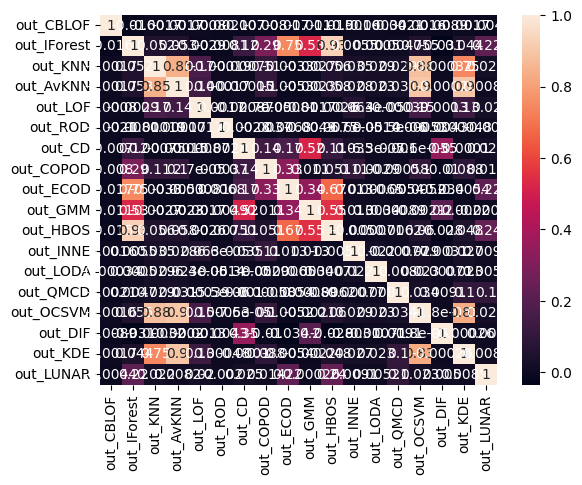

In [25]:
# 18
ax = sns.heatmap(pyod_df_small[out_algos].corr(), annot=True)
# pearson correlation between different algorithms - this tells us 
# which algorithms are returning similar results

In [26]:
# 19
pyod_df_small[out_algos].corr(method='pearson')
#This tells us which algorithms are similar i.e. detecting the same row as outlier

,out_CBLOF,out_IForest,out_KNN,out_AvKNN,out_LOF,out_ROD,out_CD,out_COPOD,out_ECOD,out_GMM,out_HBOS,out_INNE,out_LODA,out_QMCD,out_OCSVM,out_DIF,out_KDE,out_LUNAR
out_CBLOF,1.000000,-0.016282,-0.001691,-0.001661,-0.000795,-0.002144,-0.007017,-0.007995,-0.016672,-0.010900,-0.015138,-0.001554,-0.000342,-0.002108,-0.001637,-0.008911,-0.001677,-0.004418
out_IForest,-0.016282,1.000000,0.051511,0.053064,-0.002927,-0.008117,0.124250,0.292630,0.746942,0.525317,0.929292,0.005477,0.000502,0.004741,0.055018,-0.031228,0.044436,0.218136
out_KNN,-0.001691,0.051511,1.000000,0.845485,0.168016,-0.000192,-0.000751,0.105968,-0.003272,-0.002653,0.055847,0.035033,0.028519,0.029445,0.881901,-0.000316,0.745208,0.021514
out_AvKNN,-0.001661,0.053064,0.845485,1.000000,0.143189,0.000167,-0.000154,0.104509,-0.005331,-0.002348,0.057538,0.028325,0.022778,0.030671,0.900098,-0.000198,0.896656,0.008175
out_LOF,-0.000795,-0.002927,0.168016,0.143189,1.000000,0.001688,-0.000874,0.000027,-0.000814,-0.001744,-0.002604,0.063000,-0.000064,-0.000392,0.151671,-0.001315,0.133854,0.019831
out_ROD,-0.002144,-0.008117,-0.000192,0.000167,0.001688,1.000000,-0.002797,-0.003653,0.006834,-0.004885,-0.007465,-0.000066,0.001443,-0.000006,0.000532,-0.004336,0.000480,-0.001961
out_CD,-0.007017,0.124250,-0.000751,-0.000154,-0.000874,-0.002797,1.000000,0.137669,0.170593,0.515750,0.111853,0.034597,-0.000063,0.001002,-0.000076,0.353106,-0.000101,0.025465
out_COPOD,-0.007995,0.292630,0.105968,0.104509,0.000027,-0.003653,0.137669,1.000000,0.333299,0.011434,0.051124,0.108963,0.002872,-0.000583,0.103838,-0.010478,0.087877,0.013990
out_ECOD,-0.016672,0.746942,-0.003272,-0.005331,-0.000814,0.006834,0.170593,0.333299,1.000000,0.343516,0.672275,0.012599,0.000655,-0.005445,-0.005174,-0.034316,-0.005357,0.216295
out_GMM,-0.010900,0.525317,-0.002653,-0.002348,-0.001744,-0.004885,0.515750,0.011434,0.343516,1.000000,0.550209,0.013151,0.003367,0.000887,-0.002122,0.201959,-0.002205,-0.000261


In [56]:
# 20 - All model vote columns
out_algos = [c for c in pyod_input.columns if c.startswith('out_')]

# Sum of "outlier" votes per row
pyod_input['rank'] = pyod_input[out_algos].sum(axis=1)

In [57]:
# 21 - scored anomalies: the original (un-encoded) pyod_raw rows that any model flagged, with
# rank and each model's vote attached, joined on session_id (cell 3) -- not row numbers.
# Highest rank first.
out_algos = [c for c in pyod_input.columns if c.startswith('out_')]
pyod_anomalies_scored = pyod_input.loc[pyod_input['rank'] > 0, ['session_id', 'rank'] + out_algos]

pyod_output = (pyod_raw.merge(pyod_anomalies_scored, on='session_id', how='inner', validate='one_to_one')
               .sort_values(['rank', 'bytes'], ascending=False, ignore_index=True))
print(f"{len(pyod_output):,} flagged sessions of {len(pyod_raw):,}")
pd.set_option('display.max_rows', 135)
pd.set_option('display.max_colwidth', None)

374,163 flagged sessions of 3,616,571


In [29]:
# 22 - check the join: every flagged session_id found exactly once in pyod_raw, and the raw
# row's start_time matches the scored row's (start_time isn't encoded, so it's unchanged)
_chk = (pyod_input.loc[pyod_input['rank'] > 0, ['session_id', 'start_time']]
        .merge(pyod_output[['session_id', 'start_time']], on='session_id', how='left',
               suffixes=('_scored', '_raw'), indicator=True))
_chk['start_time_match'] = _chk['start_time_scored'].eq(_chk['start_time_raw'])
print(_chk['_merge'].value_counts().to_dict())
_chk['start_time_match'].value_counts()

{'both': 374163, 'left_only': 0, 'right_only': 0}


start_time_match
True    374163
Name: count, dtype: int64

In [143]:
# 23 - pyod_raw rows with rank > 0, rank attached (no per-model votes) -- joined on session_id
out_algos = [c for c in pyod_input.columns if c.startswith('out_')]
pyod_input['rank'] = pyod_input[out_algos].sum(axis=1)
rank_lookup = pyod_input.loc[pyod_input['rank'] > 0, ['session_id', 'rank']]
pyod_output = pyod_raw.merge(rank_lookup, on='session_id', how='inner', validate='one_to_one')
assert pyod_output['rank'].gt(0).all()

In [ ]:
# 24 - high-ranked sessions: a copy of pyod_output with rank >= MIN_RANK (how many models flagged
# the session), highest rank first, then most bytes. NODATA / SKIPDATA rows (log-status;
# no addresses, ports or traffic -- they score high only because every field is empty)
# are dropped.

MIN_RANK = 6
_empty = pyod_output["log-status"].isin(["NODATA", "SKIPDATA"])
_high  = pyod_output["rank"] >= MIN_RANK
pyod_output_high = (pyod_output[_high & ~_empty]
                    .sort_values(["rank", "bytes"], ascending=False, ignore_index=True)
                    .copy())
print(f"{len(pyod_output_high):,} sessions with rank >= {MIN_RANK} (of {len(pyod_output):,} flagged); "
      f"{int((_high & _empty).sum()):,} NODATA / SKIPDATA rows dropped")
# sessions per rank, split by action (ACCEPT / REJECT; "(none)" = no action value), with totals
_act = pyod_output_high["action"].astype("string").fillna("(none)")
print(f"ACCEPT {int(_act.eq('ACCEPT').sum()):,} | REJECT {int(_act.eq('REJECT').sum()):,}"
      + (f" | (none) {int(_act.eq('(none)').sum()):,}" if _act.eq("(none)").any() else ""))
print(pd.crosstab(pyod_output_high["rank"], _act, margins=True, margins_name="total")
      .sort_index(ascending=False, key=lambda ix: ix.map(lambda v: -1 if v == "total" else v))
      .to_string())
# rank and the session fields first, model votes (out_*) last. Shown with every column:
# pandas' default (20) hides the middle ones -- srcport, dstport, protocol -- behind "...".
_votes = [c for c in pyod_output_high.columns if c.startswith("out_")]
pyod_output_high = pyod_output_high[["rank"] + [c for c in pyod_output_high.columns
                                                if c != "rank" and c not in _votes] + _votes]

1,667 sessions with rank >= 6 (of 374,163 flagged); 0 NODATA / SKIPDATA rows dropped
ACCEPT 1,598 | REJECT 69
action  ACCEPT  REJECT  total
rank                         
13           0       1      1
12          19       0     19
11           0       1      1
9            4       0      4
8           21       1     22
7         1024      61   1085
6          530       5    535
total     1598      69   1667


In [59]:
# 25 - distinct combinations of HIGH_COMBO_FIELDS in pyod_output_high, with how many sessions
# each covers, most sessions first. Blank values count as their own value. Edit the list.
HIGH_COMBO_FIELDS = ["interface-id", "srcport", "dstport", "tag-asn", "tag-direction", "tag-service"]

_missing = [c for c in HIGH_COMBO_FIELDS if c not in pyod_output_high.columns]
if _missing:
    print(f"!! not in pyod_output_high, skipped: {_missing}")
_f = [c for c in HIGH_COMBO_FIELDS if c in pyod_output_high.columns]
pyod_high_combos = (pyod_output_high.groupby(_f, dropna=False).size().rename("sessions")
                    .sort_values(ascending=False).reset_index())
print(f"{len(pyod_high_combos):,} distinct combinations of {', '.join(_f)} "
      f"in {len(pyod_output_high):,} sessions")

1,661 distinct combinations of interface-id, srcport, dstport, tag-asn, tag-direction, tag-service in 1,667 sessions


In [ ]:
# 26 - per interface-id in pyod_output_high: one table of the unique combinations of
# ENI_COMBO_FIELDS, with how many sessions each covers and when the combination was first
# seen (start_time). rank is the highest rank (number of models that flagged it) among
# the combination's sessions. ENI_SORT picks the order: "first_seen" (earliest first) or
# "sessions" (most first). Blank values show as "(none)". Edit the list to change the
# fields. Tables are kept in pyod_eni_combos.
# ENI_EXCLUDE_REJECT = True leaves out sessions whose action is REJECT (blocked by the
# security group / NACL), so the tables show only traffic that got through.

ENI_COMBO_FIELDS   = ["tag-direction", "tag-service", "tag-asn"]
ENI_EXCLUDE_REJECT = False
ENI_SORT           = "first_seen"      # or "sessions"

_need = ["interface-id", "start_time", "rank"] + ENI_COMBO_FIELDS
if _miss := [c for c in _need if c not in pyod_output_high.columns]:
    raise KeyError(f"not in pyod_output_high: {_miss}")
_src = pyod_output_high
if ENI_EXCLUDE_REJECT:
    _rej = _src["action"].eq("REJECT").fillna(False).to_numpy(bool)
    print(f"left out {int(_rej.sum()):,} REJECT sessions, {int((~_rej).sum()):,} left")
    _src = _src[~_rej]
_ec = _src[_need].copy()
_ec[["interface-id"] + ENI_COMBO_FIELDS] = (_ec[["interface-id"] + ENI_COMBO_FIELDS]
                                            .astype("string").fillna("(none)"))
_sortBy, _asc = {"first_seen": (["first_seen", "sessions"], [True, False]),
                 "sessions":   (["sessions", "first_seen"], [False, True])}[ENI_SORT]
pyod_eni_combos = {}
for _eni, _d in _ec.groupby("interface-id", sort=False):
    _t = (_d.groupby(ENI_COMBO_FIELDS)
          .agg(sessions=("start_time", "size"), rank=("rank", "max"),
               first_seen=("start_time", "min"))
          .sort_values(_sortBy, ascending=_asc).reset_index())
    pyod_eni_combos[_eni] = _t
    print()
    print(f"{_eni}: {len(_t):,} unique combinations in {len(_d):,} sessions, by {ENI_SORT}")
    display(_t)


eni-f407f06e: 3 unique combinations in 30 sessions, by first_seen


,tag-direction,tag-service,tag-asn,sessions,first_seen,last_seen
0,north-south,QUIC (HTTP/3),GOOGLE - Google LLC,28,2020-05-19 01:40:02+00:00,2020-05-19 02:12:02+00:00
1,north-south,ICMP,ARTMOTION-AS ARTMOTION SH.P.K.,1,2020-05-21 18:04:54+00:00,2020-05-21 18:04:54+00:00
2,east-west,IPv6 Tunneling,(none),1,2020-06-02 08:57:02+00:00,2020-06-02 08:57:02+00:00



eni-052a0ae9057e8f2b1: 18 unique combinations in 1,341 sessions, by first_seen


,tag-direction,tag-service,tag-asn,sessions,first_seen,last_seen
0,north-south,NTP,BODATA Bo data ApS,26,2022-03-04 17:45:48+00:00,2022-05-20 07:15:16+00:00
1,north-south,NTP,EDIS-AS-EU EDIS GmbH,19,2022-03-04 20:21:48+00:00,2022-05-12 07:58:25+00:00
2,north-south,NTP,IT7NET - IT7 Networks Inc,205,2022-03-11 22:15:33+00:00,2022-06-29 16:07:59+00:00
3,north-south,NTP,Hiper Hiper A/S,19,2022-03-17 10:40:48+00:00,2022-06-10 02:03:44+00:00
4,north-south,NTP,GlobalConnect-AS31027 GlobalConnect A/S,30,2022-03-25 03:42:59+00:00,2022-07-01 01:23:56+00:00
5,north-south,NTP,DREAMSCAPE-AS-AP - Dreamscape Networks Limited,40,2022-03-25 22:42:42+00:00,2022-06-09 03:35:12+00:00
6,north-south,NTP,DEAC-AS Sabiedriba ar ierobezotu atbildibu DELSKA Latvia,25,2022-04-07 19:59:07+00:00,2022-06-17 19:17:59+00:00
7,north-south,NTP,FONIRA Fonira Telekom GmbH,29,2022-04-19 02:03:13+00:00,2022-06-27 21:26:45+00:00
8,north-south,NTP,AS-UNIXSOLUTIONS Unix-Solutions BV,26,2022-04-21 21:12:54+00:00,2022-04-27 05:00:17+00:00
9,north-south,NTP,IPACCT-AS IPACCT CABLE Ltd,10,2022-04-30 04:47:00+00:00,2022-04-30 07:22:44+00:00



eni-02b85e2a3caf5dd60: 10 unique combinations in 228 sessions, by first_seen


,tag-direction,tag-service,tag-asn,sessions,first_seen,last_seen
0,east-west,(none),(none),4,2020-03-08 02:05:52+00:00,2020-03-08 02:13:49+00:00
1,north-south,SCTP,M247 M247 Europe SRL,1,2020-03-19 02:41:18+00:00,2020-03-19 02:41:18+00:00
2,north-south,SSH,Telecom Algeria - Telecom Algeria,206,2020-03-28 10:32:07+00:00,2020-05-26 21:26:02+00:00
3,north-south,SSH,Algerian Academic Research Network - Algerian Academic Research Network,4,2020-04-09 15:19:58+00:00,2020-04-15 12:43:50+00:00
4,north-south,SCTP,OVH OVH SAS,1,2020-04-19 16:12:11+00:00,2020-04-19 16:12:11+00:00
5,east-west,ICMP,(none),1,2020-04-20 21:33:30+00:00,2020-04-20 21:33:30+00:00
6,north-south,SSH,Icosnet SPA - Icosnet SPA,6,2020-05-02 07:35:03+00:00,2020-05-03 16:40:33+00:00
7,north-south,SSH,Wataniya Telecom Algerie - Wataniya Telecom Algerie,2,2020-05-09 08:53:20+00:00,2020-05-09 08:53:20+00:00
8,north-south,GRE,VIETEL-AS-AP - Viettel Group,1,2020-07-01 03:09:39+00:00,2020-07-01 03:09:39+00:00
9,north-south,SSH,Algerian Broadcasting (Tele Diffusion d'Algerie TDA) - Algerian Broadcasting (Tele Diffusion d'Algerie TDA),2,2020-07-28 02:04:12+00:00,2020-07-28 02:04:12+00:00


... (2 outputs left out)


eni-0632c492a5b323948: 3 unique combinations in 3 sessions, by first_seen


,tag-direction,tag-service,tag-asn,sessions,first_seen,last_seen
0,north-south,GRE,AS53240 - Net Onze Provedor de Acesso a Internet Eireli,1,2020-07-03 10:59:30+00:00,2020-07-03 10:59:30+00:00
1,north-south,GRE,Sinal-AS Sinal A/S,1,2020-07-15 14:13:41+00:00,2020-07-15 14:13:41+00:00
2,north-south,GRE,TTBP-AS-AP - Triple T Broadband Public Company Limited,1,2020-07-20 14:59:13+00:00,2020-07-20 14:59:13+00:00



eni-0f324b6f6044e4ef3: 4 unique combinations in 63 sessions, by first_seen


,tag-direction,tag-service,tag-asn,sessions,first_seen,last_seen
0,east-west,(none),(none),4,2020-03-08 01:51:21+00:00,2020-03-08 01:51:21+00:00
1,north-south,NetBIOS,ARTMOTION-AS ARTMOTION SH.P.K.,57,2020-03-18 21:02:07+00:00,2020-05-18 15:07:51+00:00
2,north-south,SCTP,OVH OVH SAS,1,2020-04-19 16:08:13+00:00,2020-04-19 16:08:13+00:00
3,north-south,RDP,UAT-AF - Unique Atlantic Telecommunication,1,2020-05-14 14:55:38+00:00,2020-05-14 14:55:38+00:00


In [ ]:
# 27 - connection diagram per ENI in pyod_output_high: who each ENI talked to, one figure each.
#   middle -- the ENI (violet circle), labelled with its own address
#   left   -- countries (tag-country) of its north-south peers (blue squares), busiest at
#             the top. The top EG_TOP_N get their own node, the rest share one "other" node.
#   right  -- its east-west peers: another ENI (violet circle -- lateral movement shows up
#             here), or a private address that isn't an ENI in these logs (gray diamond:
#             another VPC, an AWS service, 100.64/10, ...)
# Line width grows with sessions (log scale). Every line is labelled with its tag-service
# -- the most common one, "+n" when there are more; a session with no tag-service (port not
# in conf/) counts as "port N" (its lower port). EG_SERVICE_LABELS = False hides the labels.
# Hover a line's dot for sessions, bytes, rank, the top 8 services with their counts, top
# ports and first / last seen. rank (on the hover and on the country / peer labels) is the
# highest rank -- number of models that flagged it -- among that line's sessions; it is left
# off when EG_SOURCE has no rank column (e.g. pyod_raw).
# An ENI's own address is the one present in every one of its records in pyod_raw (each
# ENI here has one); pyod_raw is used so a peer ENI is named even when it has no
# high-ranked sessions itself.
# EG_SOURCE picks the sessions: pyod_output_high (default) or e.g. pyod_raw, to see every
# east-west link whatever the models scored. EG_ENIS limits it to some ENIs (None = all).
# EG_EXCLUDE_REJECT = True leaves out REJECT sessions (follows ENI_EXCLUDE_REJECT from the
# table cell when that has run). Figures are kept in pyod_eni_graphs, one per ENI.

EG_SOURCE         = pyod_output_high
EG_ENIS           = None          # e.g. ["eni-02b85e2a3caf5dd60", "eni-0f324b6f6044e4ef3"]
EG_TOP_N          = 25
EG_SERVICE_LABELS = True
EG_EXCLUDE_REJECT = globals().get("ENI_EXCLUDE_REJECT", True)

_EG_ENI, _EG_CTY, _EG_OTH = "#4a3aa7", "#2a78d6", "#898781"   # violet, blue, gray
_EG_NS_LINE, _EG_EW_LINE = "rgba(42,120,214,0.45)", "rgba(74,58,167,0.85)"
_EG_INK, _EG_INK2, _EG_SURF = "#0b0b0b", "#52514e", "#fcfcfb"

_need = ["interface-id", "srcaddr", "dstaddr", "srcport", "dstport", "tag-direction",
         "tag-country", "tag-service", "action", "bytes", "start_time"]
if _miss := [c for c in _need if c not in EG_SOURCE.columns]:
    raise KeyError(f"not in EG_SOURCE: {_miss}")

# each ENI's own address: of its first record's two addresses, the one in all its records
_r   = pyod_raw.loc[pyod_raw["srcaddr"].ne("-") & pyod_raw["srcaddr"].notna(),
                    ["interface-id", "srcaddr", "dstaddr"]]
_fst = _r.groupby("interface-id", sort=False)[["srcaddr", "dstaddr"]].first()
_ipEni, _eniIp = {}, {}
for _side in ("srcaddr", "dstaddr"):
    _cand = _r["interface-id"].map(_fst[_side])
    _cov  = (_r["srcaddr"].eq(_cand) | _r["dstaddr"].eq(_cand)).groupby(_r["interface-id"]).mean()
    for _eni, _share in _cov.items():
        if _share == 1.0 and _eni not in _eniIp:
            _eniIp[_eni] = _fst.at[_eni, _side]
            _ipEni.setdefault(_eniIp[_eni], _eni)
if _noOwn := sorted(set(_r["interface-id"].unique()) - set(_eniIp)):
    print(f"!! no single own address for {len(_noOwn)} ENIs (e.g. {_noOwn[0]}) -- "
          "their east-west peers show as bare addresses")

_hasRank = "rank" in EG_SOURCE.columns
_s = EG_SOURCE[_need + (["rank"] if _hasRank else [])]
if EG_ENIS:
    _s = _s[_s["interface-id"].isin(EG_ENIS)]
if EG_EXCLUDE_REJECT:
    _rej = _s["action"].eq("REJECT").fillna(False).to_numpy(bool)
    print(f"left out {int(_rej.sum()):,} REJECT sessions, {int((~_rej).sum()):,} left")
    _s = _s[~_rej]
_s = _s.assign(_eni=_s["interface-id"].astype("string"),
               _dir=_s["tag-direction"].astype("string"),
               _svc=_s["tag-service"].astype("string"),
               _port=_s["dstport"].where(_s["dstport"].le(_s["srcport"]) | _s["srcport"].isna(),
                                         _s["srcport"]).astype("Int64").astype("string").fillna("-"))
_s["_svc"] = _s["_svc"].fillna("port " + _s["_port"])


def _egFmtBytes(b):
    for u in ("B", "kB", "MB", "GB", "TB"):
        if abs(b) < 1000 or u == "TB":
            return f"{b:,.0f} {u}" if u == "B" else f"{b:,.1f} {u}"
        b /= 1000


def _egRank(r):
    """', rank N' for a row of an edge table, '' when there is no rank."""
    v = r.get("rank") if _hasRank else None
    return f", pyod rank {int(v)}" if v is not None and pd.notna(v) else ""


def _egEdges(d, key):
    """One row per value of key (the far end): sessions, bytes, highest rank, services, top
    ports, first / last seen; most sessions first."""
    g = d.assign(_k=key.to_numpy())
    _agg = dict(sessions=("_k", "size"), bytes=("bytes", "sum"),
                first=("start_time", "min"), last=("start_time", "max"))
    if _hasRank:
        _agg["rank"] = ("rank", "max")
    t = g.groupby("_k").agg(**_agg)
    t["ports"] = g.groupby("_k")["_port"].agg(lambda x: ", ".join(x.value_counts().index[:3]))
    # services on each line, most sessions first: "SSH 120, RDP 4" and the label "SSH +1"
    _sv = (g.groupby(["_k", "_svc"]).size().rename("n").reset_index()
           .sort_values(["_k", "n"], ascending=[True, False]))
    _sv["_txt"] = _sv["_svc"] + " " + _sv["n"].map("{:,}".format)
    _grp = _sv.groupby("_k", sort=False)
    t["services"]  = _grp["_txt"].agg(lambda x: ", ".join(x.iloc[:8])
                                      + (f", ... {len(x) - 8:,} more" if len(x) > 8 else ""))
    t["svc_label"] = _grp["_svc"].agg(lambda x: x.iloc[0] + (f" +{len(x) - 1}" if len(x) > 1 else ""))
    return t.sort_values(["sessions", "bytes"], ascending=False)


def _egFold(t, n, what):
    """Keep the top n rows; the rest become one 'other (k <what>)' row."""
    if len(t) <= n:
        return t
    rest = t.iloc[n:]
    other = pd.DataFrame({"sessions": [rest["sessions"].sum()], "bytes": [rest["bytes"].sum()],
                          "first": [rest["first"].min()], "last": [rest["last"].max()],
                          "ports": ["-"], "services": ["-"], "svc_label": [""]},
                         index=[f"other ({len(rest)} {what})"])
    if "rank" in t.columns:
        other["rank"] = rest["rank"].max()
    return pd.concat([t.iloc[:n], other])


def _egN(n, word="session"):
    return f"{n:,} {word}" + ("" if n == 1 else "s")


def _egGraph(eni, d):
    own  = _eniIp.get(eni)
    ns   = d[d["_dir"].eq("north-south").fillna(False)]
    ew   = d[d["_dir"].eq("east-west").fillna(False)]
    ctyT = _egFold(_egEdges(ns, ns["tag-country"].astype("string").fillna("(none)")),
                   EG_TOP_N, "countries")
    peer = ew["dstaddr"].where(ew["srcaddr"].eq(own), ew["srcaddr"]).astype("string")
    peerT = _egFold(_egEdges(ew, peer.map(lambda a: _ipEni.get(a, a))), EG_TOP_N, "peers")

    span = max(len(ctyT), len(peerT), 2) - 1
    def spread(n):                                   # n slots from top (0) to bottom (-span)
        return [-span / 2] if n == 1 else [-i * span / (n - 1) for i in range(n)]
    hub  = (0.0, -span / 2)
    maxS = max([1] + ctyT["sessions"].tolist() + peerT["sessions"].tolist())
    width = lambda n: 1 + 5 * np.log10(n) / max(np.log10(maxS), 1)

    fig = go.Figure()
    mid = {"x": [], "y": [], "text": [], "color": [], "label": []}
    for t, x, line, dot in ((ctyT, -1.0, _EG_NS_LINE, _EG_CTY), (peerT, 1.0, _EG_EW_LINE, _EG_ENI)):
        for (name, r), y in zip(t.iterrows(), spread(len(t))):
            fig.add_scatter(x=[hub[0], x], y=[hub[1], y], mode="lines", hoverinfo="skip",
                            showlegend=False, line=dict(color=line, width=width(r.sessions)))
            # dot (hover target + label) 70% of the way out, where the lines have spread apart
            mid["x"].append(hub[0] + 0.7 * (x - hub[0])); mid["y"].append(hub[1] + 0.7 * (y - hub[1]))
            mid["color"].append(dot)
            mid["label"].append(r.svc_label if EG_SERVICE_LABELS else "")
            mid["text"].append(f"<b>{eni}  &harr;  {name}</b><br>{_egN(int(r.sessions))}, "
                               f"{_egFmtBytes(r.bytes)}{_egRank(r)}<br>services {r.services}<br>ports {r.ports}"
                               f"<br>first {str(r['first'])[:19]}<br>last  {str(r['last'])[:19]}")
    fig.add_scatter(x=mid["x"], y=mid["y"], mode="markers+text", showlegend=False,
                    text=mid["label"], textposition="top center",
                    textfont=dict(size=10, color=_EG_INK2),
                    marker=dict(size=6, color=mid["color"], line=dict(width=1.5, color=_EG_SURF)),
                    hovertext=mid["text"], hoverinfo="text")

    def nodes(names, ys, x, color, symbol, side, legend, label):
        if names:
            fig.add_scatter(x=[x] * len(names), y=ys, mode="markers+text", name=legend,
                            text=[label(n) for n in names], textposition=side,
                            textfont=dict(color=_EG_INK, size=12), hoverinfo="text",
                            hovertext=[f"<b>{label(n)}</b>" for n in names],
                            marker=dict(size=14, color=color, symbol=symbol,
                                        line=dict(width=2, color=_EG_SURF)))

    nodes(list(ctyT.index), spread(len(ctyT)), -1.0, _EG_CTY, "square", "middle left", "country",
          lambda c: f"{c}  ({int(ctyT.at[c, 'sessions']):,}{_egRank(ctyT.loc[c])})")
    _isEni = [p in _eniIp for p in peerT.index]
    _py = spread(len(peerT))
    for flag, color, symbol, legend in ((True, _EG_ENI, "circle", "peer ENI"),
                                        (False, _EG_OTH, "diamond", "other private address")):
        _n = [p for p, f in zip(peerT.index, _isEni) if f == flag]
        nodes(_n, [y for y, f in zip(_py, _isEni) if f == flag], 1.0, color, symbol, "middle right",
              legend, lambda p: f"{p}  {_eniIp.get(p, '')}  ({int(peerT.at[p, 'sessions']):,}{_egRank(peerT.loc[p])})")
    nodes([eni], [hub[1]], 0.0, _EG_ENI, "circle", "bottom center", "this ENI",
          lambda e: f"<b>{e}</b><br>{own or ''}")
    fig.data[-1].marker.size = 22

    if not len(ctyT):
        fig.add_annotation(x=-1.0, y=hub[1], text="no north-south sessions", showarrow=False,
                           font=dict(color=_EG_INK2), xanchor="right")
    if not len(peerT):
        fig.add_annotation(x=1.0, y=hub[1], text="no east-west sessions", showarrow=False,
                           font=dict(color=_EG_INK2), xanchor="left")
    h = max(300, 30 * (span + 1) + 150)
    fig.update_layout(height=h, paper_bgcolor=_EG_SURF, plot_bgcolor=_EG_SURF,
                      margin=dict(l=20, r=20, t=80, b=20),
                      font=dict(family="system-ui, sans-serif", size=12, color=_EG_INK),
                      hoverlabel=dict(bgcolor=_EG_SURF, font_color=_EG_INK),
                      legend=dict(orientation="h", x=0.01, y=1.0, yanchor="bottom", font_color=_EG_INK2),
                      title=dict(text=f"{eni}  {own or ''}: {_egN(len(ns))} north-south, "
                                      f"{_egN(len(ew))} east-west", x=0.01, xref="container",
                                 xanchor="left", font=dict(size=15, color=_EG_INK)))
    fig.update_xaxes(visible=False, range=[-1.8, 2.0])
    fig.update_yaxes(visible=False, range=[-span - 0.9, 0.7])
    return fig


pyod_eni_graphs = {}
for _eni, _d in sorted(_s.groupby("_eni"), key=lambda kv: -len(kv[1])):    # busiest ENI first
    pyod_eni_graphs[_eni] = _egGraph(_eni, _d)
    pyod_eni_graphs[_eni].show()

In [ ]:
# 27b - EXPERIMENT, copy of cell 27 with ASN names on the countries. Same diagram, but each
# country label starts with the ASNs (tag-asn) its sessions came from / went to, most
# sessions first: the top EG_ASN_TOP names, one per line under the country (names longer
# than EG_WRAP characters wrap), then "+n more". Peer labels on the right are split over
# lines too (ENI / address / sessions); the margins and row height grow to fit the labels. Hover a country for all its ASNs with session counts. Figures are kept
# in pyod_eni_graphs_asn so cell 27's pyod_eni_graphs is left alone.
# --- cell 27's notes ---
# connection diagram per ENI in pyod_output_high: who each ENI talked to, one figure each.
#   middle -- the ENI (violet circle), labelled with its own address
#   left   -- countries (tag-country) of its north-south peers (blue squares), busiest at
#             the top. The top EG_TOP_N get their own node, the rest share one "other" node.
#   right  -- its east-west peers: another ENI (violet circle -- lateral movement shows up
#             here), or a private address that isn't an ENI in these logs (gray diamond:
#             another VPC, an AWS service, 100.64/10, ...)
# Line width grows with sessions (log scale). Every line is labelled with its tag-service
# -- the most common one, "+n" when there are more; a session with no tag-service (port not
# in conf/) counts as "port N" (its lower port). EG_SERVICE_LABELS = False hides the labels.
# Hover a line's dot for sessions, bytes, rank, the top 8 services with their counts, top
# ports and first / last seen. rank (on the hover and on the country / peer labels) is the
# highest rank -- number of models that flagged it -- among that line's sessions; it is left
# off when EG_SOURCE has no rank column (e.g. pyod_raw).
# An ENI's own address is the one present in every one of its records in pyod_raw (each
# ENI here has one); pyod_raw is used so a peer ENI is named even when it has no
# high-ranked sessions itself.
# EG_SOURCE picks the sessions: pyod_output_high (default) or e.g. pyod_raw, to see every
# east-west link whatever the models scored. EG_ENIS limits it to some ENIs (None = all).
# EG_EXCLUDE_REJECT = True leaves out REJECT sessions (follows ENI_EXCLUDE_REJECT from the
# table cell when that has run). Figures are kept in pyod_eni_graphs, one per ENI.

EG_SOURCE         = pyod_output_high
EG_ENIS           = None          # e.g. ["eni-02b85e2a3caf5dd60", "eni-0f324b6f6044e4ef3"]
EG_TOP_N          = 25
EG_SERVICE_LABELS = True
EG_ASN_TOP        = 3             # ASN names shown per country
EG_WRAP           = 40            # wrap ASN names longer than this many characters
EG_EXCLUDE_REJECT = globals().get("ENI_EXCLUDE_REJECT", True)

_EG_ENI, _EG_CTY, _EG_OTH = "#4a3aa7", "#2a78d6", "#898781"   # violet, blue, gray
_EG_NS_LINE, _EG_EW_LINE = "rgba(42,120,214,0.45)", "rgba(74,58,167,0.85)"
_EG_INK, _EG_INK2, _EG_SURF = "#0b0b0b", "#52514e", "#fcfcfb"

_need = ["interface-id", "srcaddr", "dstaddr", "srcport", "dstport", "tag-direction",
         "tag-country", "tag-asn", "tag-service", "action", "bytes", "start_time"]
if _miss := [c for c in _need if c not in EG_SOURCE.columns]:
    raise KeyError(f"not in EG_SOURCE: {_miss}")

# each ENI's own address: of its first record's two addresses, the one in all its records
_r   = pyod_raw.loc[pyod_raw["srcaddr"].ne("-") & pyod_raw["srcaddr"].notna(),
                    ["interface-id", "srcaddr", "dstaddr"]]
_fst = _r.groupby("interface-id", sort=False)[["srcaddr", "dstaddr"]].first()
_ipEni, _eniIp = {}, {}
for _side in ("srcaddr", "dstaddr"):
    _cand = _r["interface-id"].map(_fst[_side])
    _cov  = (_r["srcaddr"].eq(_cand) | _r["dstaddr"].eq(_cand)).groupby(_r["interface-id"]).mean()
    for _eni, _share in _cov.items():
        if _share == 1.0 and _eni not in _eniIp:
            _eniIp[_eni] = _fst.at[_eni, _side]
            _ipEni.setdefault(_eniIp[_eni], _eni)
if _noOwn := sorted(set(_r["interface-id"].unique()) - set(_eniIp)):
    print(f"!! no single own address for {len(_noOwn)} ENIs (e.g. {_noOwn[0]}) -- "
          "their east-west peers show as bare addresses")

_hasRank = "rank" in EG_SOURCE.columns
_s = EG_SOURCE[_need + (["rank"] if _hasRank else [])]
if EG_ENIS:
    _s = _s[_s["interface-id"].isin(EG_ENIS)]
if EG_EXCLUDE_REJECT:
    _rej = _s["action"].eq("REJECT").fillna(False).to_numpy(bool)
    print(f"left out {int(_rej.sum()):,} REJECT sessions, {int((~_rej).sum()):,} left")
    _s = _s[~_rej]
_s = _s.assign(_eni=_s["interface-id"].astype("string"),
               _dir=_s["tag-direction"].astype("string"),
               _svc=_s["tag-service"].astype("string"),
               _port=_s["dstport"].where(_s["dstport"].le(_s["srcport"]) | _s["srcport"].isna(),
                                         _s["srcport"]).astype("Int64").astype("string").fillna("-"))
_s["_svc"] = _s["_svc"].fillna("port " + _s["_port"])


def _egFmtBytes(b):
    for u in ("B", "kB", "MB", "GB", "TB"):
        if abs(b) < 1000 or u == "TB":
            return f"{b:,.0f} {u}" if u == "B" else f"{b:,.1f} {u}"
        b /= 1000


def _egRank(r):
    """', rank N' for a row of an edge table, '' when there is no rank."""
    v = r.get("rank") if _hasRank else None
    return f",pyod rank {int(v)}" if v is not None and pd.notna(v) else ""


def _egEdges(d, key):
    """One row per value of key (the far end): sessions, bytes, highest rank, services, top
    ports, first / last seen; most sessions first."""
    g = d.assign(_k=key.to_numpy())
    _agg = dict(sessions=("_k", "size"), bytes=("bytes", "sum"),
                first=("start_time", "min"), last=("start_time", "max"))
    if _hasRank:
        _agg["rank"] = ("rank", "max")
    t = g.groupby("_k").agg(**_agg)
    t["ports"] = g.groupby("_k")["_port"].agg(lambda x: ", ".join(x.value_counts().index[:3]))
    # services on each line, most sessions first: "SSH 120, RDP 4" and the label "SSH +1"
    _sv = (g.groupby(["_k", "_svc"]).size().rename("n").reset_index()
           .sort_values(["_k", "n"], ascending=[True, False]))
    _sv["_txt"] = _sv["_svc"] + " " + _sv["n"].map("{:,}".format)
    _grp = _sv.groupby("_k", sort=False)
    t["services"]  = _grp["_txt"].agg(lambda x: ", ".join(x.iloc[:8])
                                      + (f", ... {len(x) - 8:,} more" if len(x) > 8 else ""))
    t["svc_label"] = _grp["_svc"].agg(lambda x: x.iloc[0] + (f" +{len(x) - 1}" if len(x) > 1 else ""))
    return t.sort_values(["sessions", "bytes"], ascending=False)


def _egFold(t, n, what):
    """Keep the top n rows; the rest become one 'other (k <what>)' row."""
    if len(t) <= n:
        return t
    rest = t.iloc[n:]
    other = pd.DataFrame({"sessions": [rest["sessions"].sum()], "bytes": [rest["bytes"].sum()],
                          "first": [rest["first"].min()], "last": [rest["last"].max()],
                          "ports": ["-"], "services": ["-"], "svc_label": [""]},
                         index=[f"other ({len(rest)} {what})"])
    if "rank" in t.columns:
        other["rank"] = rest["rank"].max()
    return pd.concat([t.iloc[:n], other])


def _egN(n, word="session"):
    return f"{n:,} {word}" + ("" if n == 1 else "s")


def _egGraph(eni, d):
    own  = _eniIp.get(eni)
    ns   = d[d["_dir"].eq("north-south").fillna(False)]
    ew   = d[d["_dir"].eq("east-west").fillna(False)]
    ctyT = _egFold(_egEdges(ns, ns["tag-country"].astype("string").fillna("(none)")),
                   EG_TOP_N, "countries")
    # ASNs per country, most sessions first: label text and hover text
    _ca = (ns.assign(_c=ns["tag-country"].astype("string").fillna("(none)"),
                     _a=ns["tag-asn"].astype("string").fillna("(none)"))
           .groupby(["_c", "_a"]).size().rename("n").reset_index()
           .sort_values(["_c", "n"], ascending=[True, False]))
    asnLines, asnHov = {}, {}
    for _c, _g in _ca.groupby("_c", sort=False):
        _names = _g["_a"].tolist()
        asnLines[_c] = ([l for a in _names[:EG_ASN_TOP] for l in textwrap.wrap(a, EG_WRAP)]
                        + ([f"+{len(_names) - EG_ASN_TOP} more"] if len(_names) > EG_ASN_TOP else []))
        asnHov[_c] = ("<br>".join(f"{a}  ({n:,})" for a, n in zip(_names[:20], _g["n"]))
                      + (f"<br>... {len(_names) - 20:,} more" if len(_names) > 20 else ""))
    peer = ew["dstaddr"].where(ew["srcaddr"].eq(own), ew["srcaddr"]).astype("string")
    peerT = _egFold(_egEdges(ew, peer.map(lambda a: _ipEni.get(a, a))), EG_TOP_N, "peers")

    span = max(len(ctyT), len(peerT), 2) - 1
    def spread(n):                                   # n slots from top (0) to bottom (-span)
        return [-span / 2] if n == 1 else [-i * span / (n - 1) for i in range(n)]
    hub  = (0.0, -span / 2)
    maxS = max([1] + ctyT["sessions"].tolist() + peerT["sessions"].tolist())
    width = lambda n: 1 + 5 * np.log10(n) / max(np.log10(maxS), 1)

    fig = go.Figure()
    mid = {"x": [], "y": [], "text": [], "color": [], "label": []}
    for t, x, line, dot in ((ctyT, -1.0, _EG_NS_LINE, _EG_CTY), (peerT, 1.0, _EG_EW_LINE, _EG_ENI)):
        for (name, r), y in zip(t.iterrows(), spread(len(t))):
            fig.add_scatter(x=[hub[0], x], y=[hub[1], y], mode="lines", hoverinfo="skip",
                            showlegend=False, line=dict(color=line, width=width(r.sessions)))
            # dot (hover target + label) 70% of the way out, where the lines have spread apart
            mid["x"].append(hub[0] + 0.7 * (x - hub[0])); mid["y"].append(hub[1] + 0.7 * (y - hub[1]))
            mid["color"].append(dot)
            mid["label"].append(r.svc_label if EG_SERVICE_LABELS else "")
            mid["text"].append(f"<b>{eni}  &harr;  {name}</b><br>{_egN(int(r.sessions))}, "
                               f"{_egFmtBytes(r.bytes)}{_egRank(r)}<br>services {r.services}<br>ports {r.ports}"
                               f"<br>first {str(r['first'])[:19]}<br>last  {str(r['last'])[:19]}")
    fig.add_scatter(x=mid["x"], y=mid["y"], mode="markers+text", showlegend=False,
                    text=mid["label"], textposition="top center",
                    textfont=dict(size=10, color=_EG_INK2),
                    marker=dict(size=6, color=mid["color"], line=dict(width=1.5, color=_EG_SURF)),
                    hovertext=mid["text"], hoverinfo="text")

    allLbl = {"left": [], "right": []}            # labels per side, to size margins / rows
    def nodes(names, ys, x, color, symbol, side, legend, label, hover=None):
        if names:
            if x:
                allLbl["left" if x < 0 else "right"] += [label(n) for n in names]
            fig.add_scatter(x=[x] * len(names), y=ys, mode="markers+text", name=legend,
                            text=[label(n) for n in names], textposition=side,
                            textfont=dict(color=_EG_INK, size=12), hoverinfo="text",
                            cliponaxis=False,
                            hovertext=[hover(n) if hover else f"<b>{label(n)}</b>" for n in names],
                            marker=dict(size=14, color=color, symbol=symbol,
                                        line=dict(width=2, color=_EG_SURF)))

    nodes(list(ctyT.index), spread(len(ctyT)), -1.0, _EG_CTY, "square", "middle left", "country",
          lambda c: "<br>".join([f"<b>{c}</b>  ({int(ctyT.at[c, 'sessions']):,}{_egRank(ctyT.loc[c])})"]
                                 + asnLines.get(c, [])),
          lambda c: f"<b>{c}</b>  ({int(ctyT.at[c, 'sessions']):,}{_egRank(ctyT.loc[c])})<br>"
                    + asnHov.get(c, ""))
    _isEni = [p in _eniIp for p in peerT.index]
    _py = spread(len(peerT))
    for flag, color, symbol, legend in ((True, _EG_ENI, "circle", "peer ENI"),
                                        (False, _EG_OTH, "diamond", "other private address")):
        _n = [p for p, f in zip(peerT.index, _isEni) if f == flag]
        nodes(_n, [y for y, f in zip(_py, _isEni) if f == flag], 1.0, color, symbol, "middle right",
              legend, lambda p: "<br>".join(x for x in (p, _eniIp.get(p, ""),
                  f"({int(peerT.at[p, 'sessions']):,}{_egRank(peerT.loc[p])})") if x))
    nodes([eni], [hub[1]], 0.0, _EG_ENI, "circle", "bottom center", "this ENI",
          lambda e: f"<b>{e}</b><br>{own or ''}")
    fig.data[-1].marker.size = 22

    if not len(ctyT):
        allLbl["left"].append("no north-south sessions")
        fig.add_annotation(x=-1.0, y=hub[1], text="no north-south sessions", showarrow=False,
                           font=dict(color=_EG_INK2), xanchor="right")
    if not len(peerT):
        allLbl["right"].append("no east-west sessions")
        fig.add_annotation(x=1.0, y=hub[1], text="no east-west sessions", showarrow=False,
                           font=dict(color=_EG_INK2), xanchor="left")
    # label sizes: widest line per side sets that margin (~7.5 px per character at size 12),
    # most lines in one label sets the row height (~16 px per line)
    def _lines(lbls):
        return [re.sub(r"<[^>]+>", "", l) for x in lbls for l in x.split("<br>")]
    _ml = lambda side: max([len(l) for l in _lines(allLbl[side])] + [0])
    _maxLn = max([x.count("<br>") + 1 for v in allLbl.values() for x in v] + [1])
    _row = max(30, 16 * _maxLn + 8)
    h = max(300, _row * (span + 1) + 150)
    fig.update_layout(height=h, paper_bgcolor=_EG_SURF, plot_bgcolor=_EG_SURF,
                      margin=dict(l=int(30 + 7.5 * _ml("left")), r=int(30 + 7.5 * _ml("right")),
                                  t=80, b=20),
                      font=dict(family="system-ui, sans-serif", size=12, color=_EG_INK),
                      hoverlabel=dict(bgcolor=_EG_SURF, font_color=_EG_INK),
                      legend=dict(orientation="h", x=0.01, y=1.0, yanchor="bottom", font_color=_EG_INK2),
                      title=dict(text=f"{eni}  {own or ''}: {_egN(len(ns))} north-south, "
                                      f"{_egN(len(ew))} east-west", x=0.01, xref="container",
                                 xanchor="left", font=dict(size=15, color=_EG_INK)))
    fig.update_xaxes(visible=False, range=[-1.08, 1.08])   # labels sit in the margins
    fig.update_yaxes(visible=False, range=[-span - 0.9, 0.7])
    return fig


pyod_eni_graphs_asn = {}
for _eni, _d in sorted(_s.groupby("_eni"), key=lambda kv: -len(kv[1])):    # busiest ENI first
    pyod_eni_graphs_asn[_eni] = _egGraph(_eni, _d)
    pyod_eni_graphs_asn[_eni].show()

In [142]:
# 28 - write pyod_output to the output folder as parquet and CSV, named after the AWS account
# and today's date, e.g. output/pyod-output-637602092272-november-10-2026.parquet (and .csv).
# Adds a "type" field first, saying which detection made the rows (as flows-dbscan and
# kmeans-mark-3 do). The account comes from the account-id of the loaded sessions (pyod_raw);
# several accounts are joined with "+". OUT_DIR is the folder, created if it isn't there.
OUT_DIR   = "output"
PYOD_TYPE = "pyod anomaly detection"

if "type" in pyod_output.columns:
    pyod_output = pyod_output.drop(columns="type")
pyod_output.insert(0, "type", PYOD_TYPE)

if "account-id" not in pyod_raw.columns:
    raise KeyError("pyod_raw has no 'account-id' column -- can't name the file")
_accts = sorted(pyod_raw["account-id"].dropna().astype(str).str.strip().unique())
_accts = [a for a in _accts if a and a != "-"]
if not _accts:
    raise ValueError("no account-id values in pyod_raw -- can't name the file")
_now  = pd.Timestamp.now()
_base = os.path.join(OUT_DIR, f"pyod-output-{'+'.join(_accts)}-"
                              f"{_now.strftime('%B').lower()}-{_now.day}-{_now.year}")
os.makedirs(OUT_DIR, exist_ok=True)
PYOD_OUT_PARQUET = _base + ".parquet"
PYOD_OUT_CSV     = _base + ".csv"
pyod_output.to_parquet(PYOD_OUT_PARQUET, index=False)
pyod_output.to_csv(PYOD_OUT_CSV, index=False)
print(f"wrote {len(pyod_output):,} rows, {pyod_output.shape[1]} columns to")
print(f"  {PYOD_OUT_PARQUET}")
print(f"  {PYOD_OUT_CSV}")

wrote 373,247 rows, 32 columns to
  output\pyod-output-637602092272-november-10-2026.parquet
  output\pyod-output-637602092272-november-10-2026.csv


In [37]:
# 29
from IPython.display import Audio, display
import numpy as np

# simple beep
display(Audio(data=np.sin(2*np.pi*440*np.linspace(0, 1, 44100)), rate=44100, autoplay=True))
